In [7]:
# PyTorch: tensors, neural network layers, optimizers
import torch
import torch.nn as nn 
import torch.optim as optim
# torchvision: MNIST dataset and image preprocessing
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
# Plotting and evaluation metrics
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

In [8]:
transform = transforms.Compose([
    transforms.ToTensor(),                      # PIL image -> tensor [1, 28, 28], pixel values scaled to [0, 1]
    transforms.Normalize((0.1307), (0.3081))    # standardize using MNIST's mean and std
])

# Dataset lives in the project-root data/ folder (the notebook runs from notebooks/)
train_data = datasets.MNIST(root="../data", train=True,  download=True, transform=transform)   #   60.000 
test_data  = datasets.MNIST(root="../data", train=False, download=True, transform=transform)   #   10.000

# Every image goes through the transform

In [9]:
# Loaders feed the data in batches; training data is shuffled every epoch,
# test data keeps a fixed order (larger batches are fine since no gradients are computed)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=1000, shuffle=False)

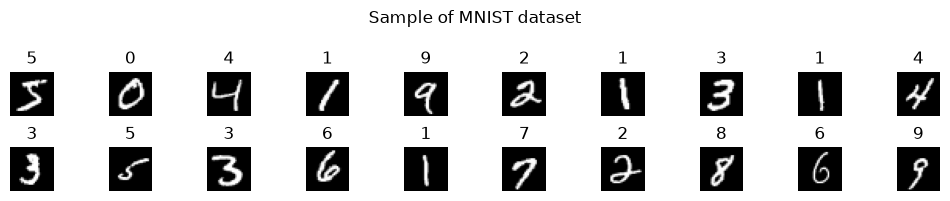

In [10]:
# Plot the first n images of the dataset in a 2-row grid, each titled with its label
def show_sample(dataset, n=20):
    plt.figure(figsize=(10, 2))
    for i in range(n):
        image, label = dataset[i]
        plt.subplot(2, n//2, i+1)
        plt.imshow(image.squeeze(), cmap='gray')   # squeeze: [1, 28, 28] -> [28, 28] for imshow
        plt.title(label)
        plt.axis('off')
    plt.suptitle("Sample of MNIST dataset", fontsize = 12)
    plt.tight_layout()
    plt.show()

show_sample(train_data)

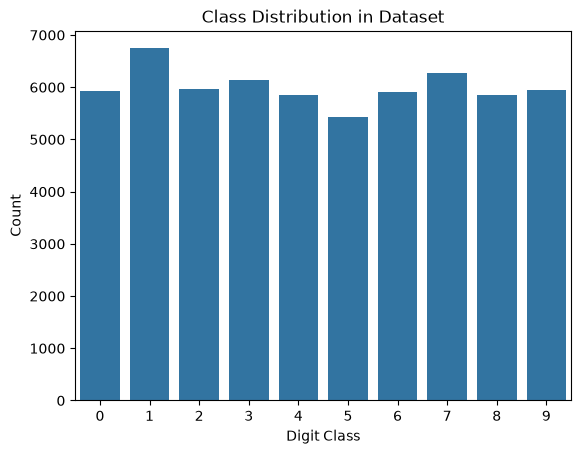

In [11]:
# Checking Class Distribution
# (a roughly equal count per digit means the dataset is balanced)

labels = [label for _ , label in train_data]
sns.countplot(x=labels)
plt.title("Class Distribution in Dataset")
plt.xlabel("Digit Class")
plt.ylabel("Count")
plt.show()

In [12]:
# Small CNN: two conv + pool blocks extract features, two fully connected layers classify them
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding =1)     # 1 input channel (grayscale) -> 16 feature maps, 3x3 kernel
        self.pool = nn.MaxPool2d(2, 2)                   # halves height and width
        self.conv2 = nn.Conv2d(16, 32, 3, padding = 1)   # 16 -> 32 feature maps
        self.fc1 = nn.Linear(32 * 7 * 7, 128)            # 28x28 pooled twice -> 7x7, with 32 channels
        self.fc2 = nn.Linear(128, 10)                    # one output score (logit) per digit

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # [B, 1, 28, 28] -> [B, 16, 14, 14]
        x = self.pool(torch.relu(self.conv2(x)))   # -> [B, 32, 7, 7]
        x = x.view(-1, 32 * 7 * 7)                 # flatten to [B, 1568]
        x = torch.relu(self.fc1(x))
        return self.fc2(x)                         # raw logits; softmax is applied inside the loss

model = CNNModel()

In [13]:
criterion = nn.CrossEntropyLoss()                       # standard loss for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.001)    # updates the model weights

In [14]:
epochs = 5
train_losses = []

for epoch in range(epochs):
    model.train()                          # training mode
    running_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()              # clear gradients from the previous batch
        outputs = model(images)            # forward pass
        loss = criterion(outputs, labels)
        loss.backward()                    # backpropagation: compute gradients
        optimizer.step()                   # update weights
        running_loss += loss.item()
    average_loss = running_loss / len(train_loader)   # mean loss over all batches in this epoch
    train_losses.append(average_loss)
    print(f"Epoch: [{epoch+1}/{epochs}], Loss: {average_loss:.4f}")

Epoch: [1/5], Loss: 0.1540
Epoch: [2/5], Loss: 0.0468
Epoch: [3/5], Loss: 0.0332
Epoch: [4/5], Loss: 0.0244
Epoch: [5/5], Loss: 0.0176


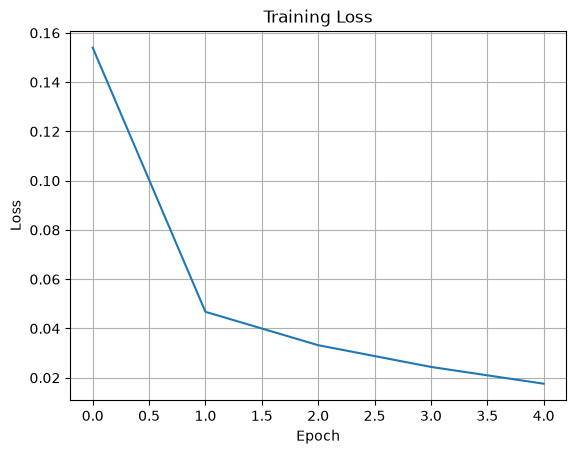

In [15]:
# Loss per epoch; a decreasing curve means the model is learning
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [16]:
# Evaluate on the test set and collect every prediction
model.eval()                     # evaluation mode
all_preds = []
all_labels = []

with torch.no_grad():            # no gradients needed for inference: faster, less memory
    for images, labels in test_loader:
        output = model(images)
        _, predicted = torch.max(output, 1)   # index of the highest score = predicted digit
        all_preds.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

# Precision, recall and F1-score for each digit
print("\n Report")
print(classification_report(all_labels, all_preds))


 Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.98      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.97      1.00      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



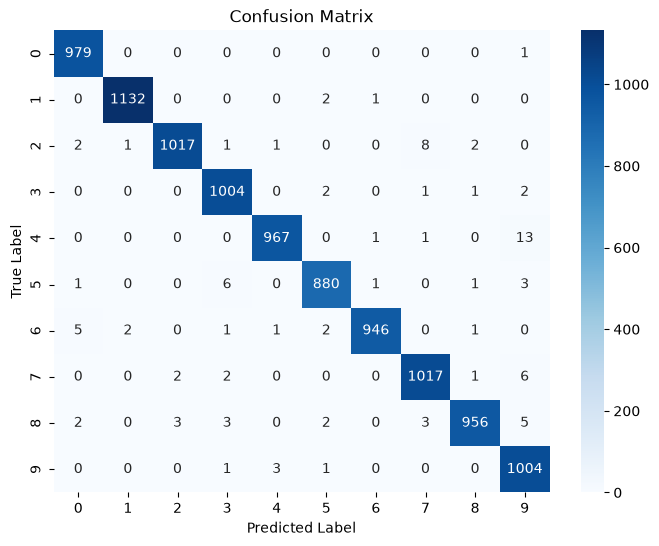

In [17]:
# Confusion Matrix
# Rows = true digit, columns = predicted digit. The diagonal holds correct predictions;
# anything off the diagonal shows which digits get confused with each other.

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

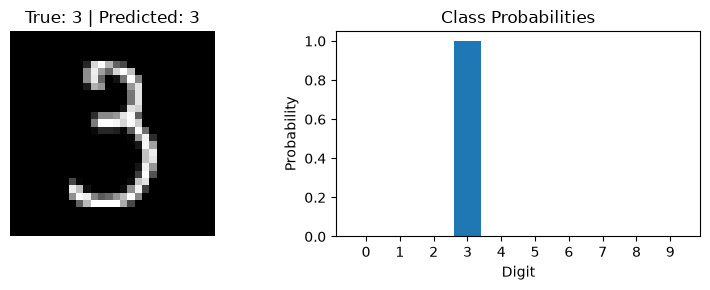

In [20]:
# Testing the model on a single image

def predict_single(dataset, index):
    model.eval()
    image, label = dataset[index]
    with torch.no_grad():
        output = model(image.unsqueeze(0))       # add batch dimension: [1, 1, 28, 28]
        probs = torch.softmax(output, dim=1).squeeze()   # logits -> probabilities that sum to 1
        predicted = probs.argmax().item()

    # Left: the image with its true and predicted label
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True: {label} | Predicted: {predicted}")
    plt.axis('off')

    # Right: how confident the model is in each digit
    plt.subplot(1, 2, 2)
    plt.bar(range(10), probs.numpy())
    plt.xticks(range(10))
    plt.title("Class Probabilities")
    plt.xlabel("Digit")
    plt.ylabel("Probability")
    plt.tight_layout()
    plt.show()

# Pick a random test image
predict_single(test_data, np.random.randint(len(test_data)))